In [ ]:
!pip install transformers[torch] datasets evaluate sacrebleu accelerate seaborn matplotlib jiwer -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 59.2 MB/s eta 0:00:00


In [ ]:
import torch
import json
import os
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GroupShuffleSplit
from datasets import Dataset, DatasetDict
from transformers import (
    AutoModelForSeq2SeqLM,
    AutoTokenizer,
    DataCollatorForSeq2Seq,
    Seq2SeqTrainingArguments,
    Seq2SeqTrainer,
    EarlyStoppingCallback
)
from google.colab import drive

# 1. Mount Drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# 2. Define Paths
# Path to your NEW dataset (Upload this to Drive or Colab first)
dataset_file = "/content/drive/MyDrive/nllb_multilingual_assertive_dataset.json"

# Path to the PREVIOUSLY TRAINED model (from the Word Training step)
# We try to load this first. If not found, we fall back to the base NLLB model.
pretrained_model_path = "/content/drive/MyDrive/Final_NLLB_Marma_Model"
output_model_path = "/content/drive/MyDrive/Final_NLLB_Assertive_Model"

print(f"📂 Dataset: {dataset_file}")
print(f"🤖 Loading Model from: {pretrained_model_path}")

📂 Dataset: /content/drive/MyDrive/nllb_multilingual_assertive_dataset.json
🤖 Loading Model from: /content/drive/MyDrive/Final_NLLB_Marma_Model


In [ ]:
import pandas as pd
# 1. Load JSON
# The JSON structure is nested: [{'translation': {'src': '...', 'tgt': '...'}}, ...]
# We need to flatten it first.
with open(dataset_file, 'r', encoding='utf-8') as f:
    data = json.load(f)

# Extract inner dictionary
flattened_data = [item['translation'] for item in data]
df = pd.DataFrame(flattened_data)

print(f"✅ Loaded {len(df)} rows.")
print("Sample:\n", df.head(3))

# 2. GROUPED SPLIT (70% Train, 30% Test)
# We group by 'src' so that if "I am tom" appears 3 times (for 3 diff languages),
# ALL of them go to Train OR ALL go to Test. No mixing!
splitter = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=42)
train_inds, test_inds = next(splitter.split(df, groups=df['src']))

train_df = df.iloc[train_inds]
test_df = df.iloc[test_inds]

print(f"\n📊 Split Statistics:")
print(f"   Train Set: {len(train_df)} rows (70%)")
print(f"   Test Set:  {len(test_df)} rows (30%)")

# 3. Format for NLLB
# We use the prompt: "Translate {src_lang} to {tgt_lang}: {src_text}"
def format_nllb(row):
    input_text = f"Translate {row['src_lang']} to {row['tgt_lang']}: {row['src']}"
    target_text = row['tgt']
    return {"input_text": input_text, "target_text": target_text}

# Convert to HF Datasets
train_dataset = Dataset.from_pandas(train_df).map(format_nllb)
test_dataset = Dataset.from_pandas(test_df).map(format_nllb)

print("✅ Data formatting complete.")

✅ Loaded 65138 rows.
Sample:
               src                 tgt  src_lang  tgt_lang
0  I'm not bossy.      আমি জোরজার নই।  eng_Latn  ben_Beng
1  I'm not bossy.  nga ana kyasu moh.  eng_Latn  mrm_Latn
2  I'm not bossy.  ঙা আনা ক্যাসু মোহ।  eng_Latn  mrm_Beng

📊 Split Statistics:
   Train Set: 45600 rows (70%)
   Test Set:  19538 rows (30%)


Map:   0%|          | 0/45600 [00:00<?, ? examples/s]

Map:   0%|          | 0/19538 [00:00<?, ? examples/s]

✅ Data formatting complete.


In [ ]:
# 1. Load Model & Tokenizer
# Check if your drive model exists, otherwise use base NLLB
if os.path.exists(pretrained_model_path):
    print(f"🔄 Loading weights from your Drive: {pretrained_model_path}")
    model_checkpoint = pretrained_model_path
else:
    print("⚠️ Drive model not found! Starting from base 'facebook/nllb-200-distilled-600M'")
    model_checkpoint = "facebook/nllb-200-distilled-600M"

tokenizer = AutoTokenizer.from_pretrained(model_checkpoint)
model = AutoModelForSeq2SeqLM.from_pretrained(model_checkpoint)

# Ensure tokenizer handles our English-style prompts
tokenizer.src_lang = "eng_Latn"
tokenizer.tgt_lang = "eng_Latn"

# 2. Tokenize Function
def preprocess_function(examples):
    inputs = examples["input_text"]
    targets = examples["target_text"]

    # Tokenize input & target
    model_inputs = tokenizer(inputs, max_length=128, truncation=True)
    labels = tokenizer(text_target=targets, max_length=128, truncation=True)

    model_inputs["labels"] = labels["input_ids"]
    return model_inputs

# Apply Tokenization
print("⏳ Tokenizing datasets...")
tokenized_train = train_dataset.map(preprocess_function, batched=True, remove_columns=train_dataset.column_names)
tokenized_test = test_dataset.map(preprocess_function, batched=True, remove_columns=test_dataset.column_names)

data_collator = DataCollatorForSeq2Seq(tokenizer, model=model)
print("✅ Tokenization Ready.")

🔄 Loading weights from your Drive: /content/drive/MyDrive/Final_NLLB_Marma_Model


The tokenizer you are loading from '/content/drive/MyDrive/Final_NLLB_Marma_Model' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.


⏳ Tokenizing datasets...


Map:   0%|          | 0/45600 [00:00<?, ? examples/s]

Map:   0%|          | 0/19538 [00:00<?, ? examples/s]

✅ Tokenization Ready.


In [ ]:
args = Seq2SeqTrainingArguments(
    output_dir="./nllb_assertive_results",

    # Evaluation & Saving Strategy
    eval_strategy="steps",
    eval_steps=500,               # Check validation loss every 500 steps
    save_strategy="steps",
    save_steps=500,
    logging_steps=100,            # Log training loss often for the graph

    # Hyperparameters
    learning_rate=2e-5,
    per_device_train_batch_size=32, # Faster processing
    per_device_eval_batch_size=32,
    num_train_epochs=5,             # 5 epochs allows good convergence
    weight_decay=0.01,

    # Optimization
    save_total_limit=2,             # Save space
    load_best_model_at_end=True,    # Always keep the best model (lowest val loss)
    metric_for_best_model="eval_loss",
    fp16=torch.cuda.is_available(), # Enable GPU acceleration
    report_to="none"
)

trainer = Seq2SeqTrainer(
    model=model,
    args=args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_test,
    data_collator=data_collator,
    tokenizer=tokenizer,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=3)] # Stop if valid loss stops improving
)

print("🚀 Starting Training...")
trainer.train()
print("✅ Training Complete.")

/tmp/ipython-input-1323015495.py:26: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Seq2SeqTrainer.__init__`. Use `processing_class` instead.
  trainer = Seq2SeqTrainer(


🚀 Starting Training...


Step,Training Loss,Validation Loss
500,1.918100,1.789207
1000,1.743800,1.626585
1500,1.643000,1.527283
2000,1.552000,1.458093
2500,1.441300,1.404589
3000,1.376200,1.365050
3500,1.371400,1.330498
4000,1.324100,1.307259
4500,1.281700,1.288870
5000,1.228800,1.270656


There were missing keys in the checkpoint model loaded: ['model.encoder.embed_tokens.weight', 'model.decoder.embed_tokens.weight', 'lm_head.weight'].


✅ Training Complete.


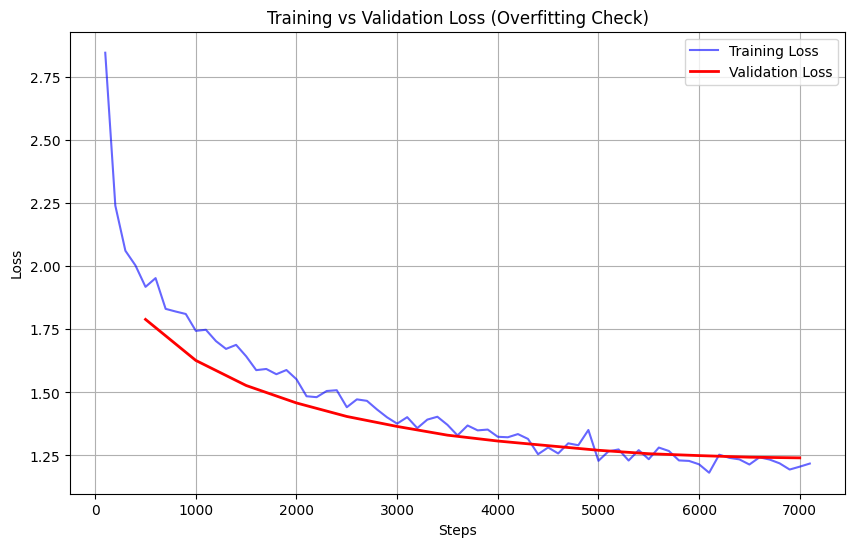

In [ ]:
# Extract logs
log_history = trainer.state.log_history

# Filter data
train_loss = []
train_steps = []
eval_loss = []
eval_steps = []

for entry in log_history:
    if 'loss' in entry:
        train_loss.append(entry['loss'])
        train_steps.append(entry['step'])
    if 'eval_loss' in entry:
        eval_loss.append(entry['eval_loss'])
        eval_steps.append(entry['step'])

# Plotting
plt.figure(figsize=(10, 6))
plt.plot(train_steps, train_loss, label='Training Loss', color='blue', alpha=0.6)
plt.plot(eval_steps, eval_loss, label='Validation Loss', color='red', linewidth=2)

plt.xlabel('Steps')
plt.ylabel('Loss')
plt.title('Training vs Validation Loss (Overfitting Check)')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
print(f"💾 Saving Final Model to {output_model_path}...")
trainer.save_model(output_model_path)
tokenizer.save_pretrained(output_model_path)
print("✅ Model Saved Successfully!")

# --- QUICK INFERENCE TEST ---
from transformers import pipeline
translator = pipeline("translation", model=output_model_path, tokenizer=output_model_path, device=0)

# Test Inputs from your dataset style
test_prompts = [
    "Translate eng_Latn to ben_Beng: I am confident.",
    "Translate eng_Latn to mrm_Latn: Don't be shy.",
    "Translate eng_Latn to mrm_Beng: Speak up."
]

print("\n--- Testing Predictions ---")
for prompt in test_prompts:
    # Extract src_lang and tgt_lang from the prompt
    parts = prompt.split(' ')
    src_lang = parts[1]
    tgt_lang = parts[3].replace(':', '')

    # Pass src_lang and tgt_lang to the translator
    res = translator(prompt, max_length=128, src_lang=src_lang, tgt_lang=tgt_lang)
    print(f"Input:  {prompt}")
    print(f"Output: {res[0]['translation_text']}")
    print("-" * 30)


💾 Saving Final Model to /content/drive/MyDrive/Final_NLLB_Assertive_Model...
✅ Model Saved Successfully!


The tokenizer you are loading from '/content/drive/MyDrive/Final_NLLB_Assertive_Model' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.
Device set to use cuda:0



--- Testing Predictions ---
Input:  Translate eng_Latn to ben_Beng: I am confident.
Output: আমি আত্মবিশ্বাসী।
------------------------------
Input:  Translate eng_Latn to mrm_Latn: Don't be shy.
Output: ma khyate.
------------------------------
Input:  Translate eng_Latn to mrm_Beng: Speak up.
Output: ।।।।।।।
------------------------------


In [ ]:
import evaluate
from tqdm.auto import tqdm
import pandas as pd

# Load Metrics
sacrebleu = evaluate.load("sacrebleu")
wer_metric = evaluate.load("wer")
cer_metric = evaluate.load("cer")

print("\n--- Running Detailed Evaluation (Per Direction) ---")

# We will group predictions by direction
results_by_dir = {}

model.eval()
device = "cuda" if torch.cuda.is_available() else "cpu"
model.to(device)

# Iterate through Test Set
# (For speed, you can limit this. Remove [:2000] to run on ALL 19k rows)
test_subset = test_dataset.select(range(min(2000, len(test_dataset))))

for item in tqdm(test_subset, desc="Evaluating"):
    # Generate
    input_ids = tokenizer(item["input_text"], return_tensors="pt").input_ids.to(device)
    with torch.no_grad():
        outputs = model.generate(input_ids, max_new_tokens=128)

    pred = tokenizer.decode(outputs[0], skip_special_tokens=True).strip()
    ref = item["target_text"].strip()
    # Fix: Create 'direction' from existing 'src_lang' and 'tgt_lang'
    direction = f"{item['src_lang']}-{item['tgt_lang']}"

    if direction not in results_by_dir:
        results_by_dir[direction] = {"preds": [], "refs": []}

    results_by_dir[direction]["preds"].append(pred)
    results_by_dir[direction]["refs"].append(ref)

# Compute Scores
final_scores = []

for direction, data in results_by_dir.items():
    preds = data["preds"]
    refs = data["refs"]

    # BLEU
    bleu = sacrebleu.compute(predictions=preds, references=[[r] for r in refs])["score"]

    # WER & CER
    wer = wer_metric.compute(predictions=preds, references=refs)
    cer = cer_metric.compute(predictions=preds, references=refs)

    # Accuracies
    wa = max(0, 1 - wer) * 100  # Word Accuracy %
    ca = max(0, 1 - cer) * 100  # Char Accuracy %

    final_scores.append({
        "Direction": direction,
        "BLEU": bleu,
        "WER": wer,
        "CER": cer,
        "WA (%)": wa,
        "CA (%)": ca,
        "Samples": len(preds)
    })

# Show Table
df_results = pd.DataFrame(final_scores).sort_values("Direction")
print("\n📊 Detailed Scores per Direction:")
print(df_results.to_markdown(index=False))


--- Running Detailed Evaluation (Per Direction) ---


Evaluating:   0%|          | 0/2000 [00:00<?, ?it/s]


📊 Detailed Scores per Direction:
| Direction         |    BLEU |      WER |       CER |   WA (%) |   CA (%) |   Samples |
|:------------------|--------:|---------:|----------:|---------:|---------:|----------:|
| ben_Beng-eng_Latn | 68.9989 | 0.241055 | 0.162996  |  75.8945 |  83.7004 |       161 |
| ben_Beng-mrm_Beng | 10.1999 | 0.78424  | 0.532446  |  21.576  |  46.7554 |       161 |
| ben_Beng-mrm_Latn |  8.7207 | 0.697897 | 0.438614  |  30.2103 |  56.1386 |       161 |
| eng_Latn-ben_Beng | 62.5718 | 0.204586 | 0.159262  |  79.5414 |  84.0738 |       172 |
| eng_Latn-mrm_Beng | 12.4043 | 0.761649 | 0.508401  |  23.8351 |  49.1599 |       172 |
| eng_Latn-mrm_Latn | 10.6791 | 0.700544 | 0.453643  |  29.9456 |  54.6357 |       172 |
| mrm_Beng-ben_Beng | 15.3497 | 0.651489 | 0.510476  |  34.8511 |  48.9524 |       170 |
| mrm_Beng-eng_Latn | 18.1765 | 0.723708 | 0.530065  |  27.6292 |  46.9935 |       170 |
| mrm_Beng-mrm_Latn | 76.064  | 0.143389 | 0.0389447 |  85.6611 |  96.1055 |

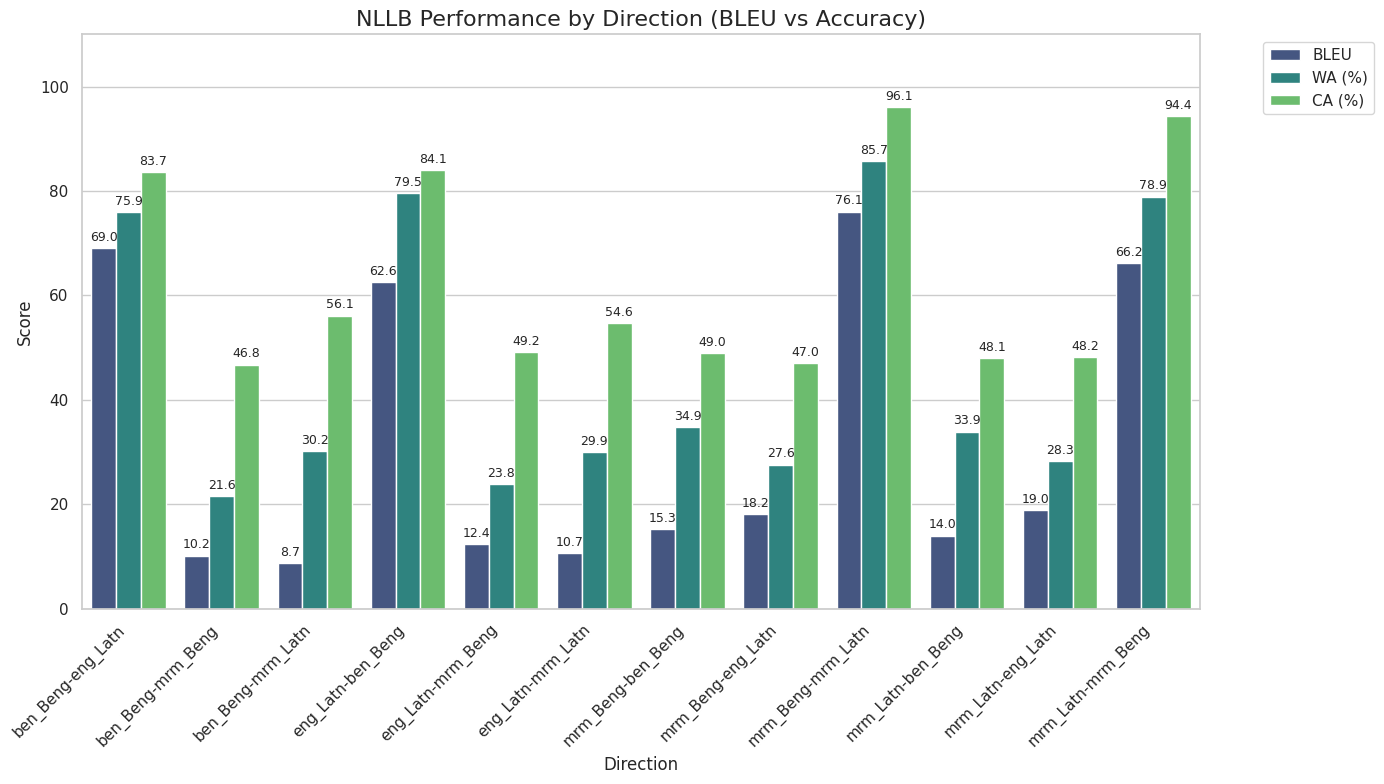

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Reshape for Plotting
df_melt = df_results.melt(id_vars=["Direction"], value_vars=["BLEU", "WA (%)", "CA (%)"],
                          var_name="Metric", value_name="Score")

plt.figure(figsize=(14, 8))
sns.set_theme(style="whitegrid")

# Create Bar Plot
chart = sns.barplot(
    data=df_melt,
    x="Direction",
    y="Score",
    hue="Metric",
    palette="viridis"
)

plt.xticks(rotation=45, ha='right')
plt.title("NLLB Performance by Direction (BLEU vs Accuracy)", fontsize=16)
plt.ylim(0, 110)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')

# Add values on bars
for container in chart.containers:
    chart.bar_label(container, fmt='%.1f', padding=3, size=9)

plt.tight_layout()
plt.show()